# LSST Y1 × DESI: up to which $k_\mathrm{max}$ is linear bias enough?

The forecast fits the DESI band powers $C_\ell^{gg}$ of thin redshift bins with
linear galaxy bias, $\delta_g = b_1\,\delta$: the galaxy density contrast
$\delta_g$ is the matter density contrast $\delta$ times one number $b_1$ per
bin. That is exact on large scales and fails on small ones, where higher-order
bias terms grow with the wavenumber $k$. This notebook answers two questions.

1. **Up to which scale cut $k_\mathrm{max}$ does a linear-bias fit stay
   unbiased?** The truth is one-loop: model A of `notes/higher_order_bias`,
   with the quadratic bias $b_2$ on its Lazeyras et al. calibration
   $b_2(b_1)$ (arXiv:1511.01096), the tidal bias $b_{s^2}$ on co-evolution,
   and four brackets around that point. The fit is linear bias on each rung of
   the ladder of `notes/correlated_bias_prior` (tied, baseline, pessimistic,
   independent). Every fit is scored for $(w_0, w_a)$, $\Omega_m$ and $A_s$,
   on the four bin layouts ($\Delta d_\mathrm{com} = 62$ Mpc and
   $\Delta z = 0.02$, $0.05$, $0.2$) and at every cut
   $k_\mathrm{max} = 0.05, 0.075, \ldots, 0.25\,h/\mathrm{Mpc}$.
2. **Does the accuracy test of `notes/correlated_bias_prior` (the v1 note)
   give the same verdict for $\Omega_m$ and $A_s$?** That note scored its
   known bias drifts and its 2000 random truths for $(w_0, w_a)$ only.

**Symbols.** $D(z)$ is the linear growth factor with $D(0) = 1$; $\Omega_m$ the
matter density today in units of the critical density; $A_s$ the amplitude of
the primordial curvature power spectrum, sampled as `As_1e9` $= 10^9 A_s$; and
$w(a) = w_0 + w_a(1 - a)$ the dark-energy equation of state, with $a$ the scale
factor. A "shift" is the distance of the fitted parameter from the truth in
units of the fit's own marginalized error $\sigma$ (for $(w_0, w_a)$, of its
error ellipse). A fit is called unbiased when every shift is below $\sigma/3$,
the v1 note's threshold.

**What $k_\mathrm{max}$ means.** Every $k_\mathrm{max}$ here is the $z = 0$
value of a per-bin cut. Bin $i$, with mean redshift $\bar z_i$, keeps a band
while the non-Limber ultraviolet fraction
$|C_\ell^\mathrm{UV}|/(|C_\ell^\mathrm{UV}| + |C_\ell^\mathrm{IR}|)$ stays below
$\alpha = 0.05$ (arXiv:2603.13031), where the two pieces are the band power
from the power spectrum above and below $k_\mathrm{max}/D(\bar z_i)$. The kept
bands are intersected with the shipped mask, which caps every bin at
$k = 0.1185\,\mathrm{Mpc}^{-1}$ with no growth scaling.

**Inputs and outputs.** The notebook reads the caches of
`EXAMPLE_EVALUATE_FISHER.ipynb` without changing them: its linear derivatives,
its per-bin bias derivatives and its scale cuts. It evaluates only the model A
truths, and caches them in `chains/`. Its figures and data go to
`notes/linear_bias_kmax`, whose PDF explains the results.

## 1. Set up Python and the Fisher module

Imports, the paths to CosmoLike and to the project's interface, and the figure
style shared by the project's notebooks (STIX fonts, no top or right ticks, a
faint grid). The project's Fisher module, imported as `fm`, evaluates the
model A data vectors in section 3.

In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
import json
import os
import pickle
import subprocess
import sys
import time
os.environ['OMP_NUM_THREADS'] = '8'
import numpy as np
import pandas as pd
import matplotlib
from matplotlib import pyplot as plt
from IPython.display import Image, display

ROOTDIR = os.environ['ROOTDIR']
os.chdir(ROOTDIR)
sys.path.insert(0, ROOTDIR + '/external_modules/code/cosmolike_core')
sys.path.insert(0, ROOTDIR + '/projects/lssty1xdesi/interface')
import cosmolike_notebook_utils as cnu
import cosmolike_lssty1xdesi_fisher as fm

matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams['font.family'] = 'STIXGeneral'
matplotlib.rcParams['mathtext.rm'] = 'Bitstream Vera Sans'
matplotlib.rcParams['mathtext.it'] = 'Bitstream Vera Sans:italic'
matplotlib.rcParams['mathtext.bf'] = 'Bitstream Vera Sans:bold'
matplotlib.rcParams['xtick.bottom'] = True
matplotlib.rcParams['xtick.top'] = False
matplotlib.rcParams['ytick.right'] = False
matplotlib.rcParams['axes.edgecolor'] = 'black'
matplotlib.rcParams['axes.linewidth'] = '1.0'
matplotlib.rcParams['axes.labelsize'] = 'medium'
matplotlib.rcParams['axes.grid'] = True
matplotlib.rcParams['grid.linewidth'] = '0.0'
matplotlib.rcParams['grid.alpha'] = '0.18'
matplotlib.rcParams['grid.color'] = 'lightgray'
matplotlib.rcParams['legend.labelspacing'] = 0.77
matplotlib.rcParams['savefig.bbox'] = 'tight'
matplotlib.rcParams['savefig.format'] = 'pdf'
matplotlib.rcParams['text.usetex'] = False
pd.set_option('display.float_format', '{:.4g}'.format)

## 2. Settings and the linear notebook's caches

The settings fix what is compared.

- `COSMO`: the seven cosmological parameters of the Fisher matrices, all with
  flat priors.
- `INVCOV_SCALE`: the DESI covariance is computed for 14,000 deg$^2$; its
  inverse is rescaled to the survey's 12,300 deg$^2$.
- `SHIFT_THRESHOLD` $= 1/3$: the v1 note's threshold. `SINGLE_PARAMS`: the
  parameters scored one at a time, $\Omega_m$ and $A_s$, next to the joint
  $(w_0, w_a)$ score.
- `KMAX_V1` $= 0.075\,h/\mathrm{Mpc}$: the cut of the v1 note's accuracy test.
- `LAYOUTS`: each layout's dataset and the cache of the linear notebook, with
  that notebook's accuracy settings. The truths are evaluated with the same
  settings, so that the difference between a truth and the linear vector holds
  the one-loop terms and nothing else.

The second cell reads each layout's covariance and mask. `kept_inverse` builds
the inverse covariance on the entries a cut keeps, and `prior_diagonal`
recovers the Gaussian priors on the per-group velocity dispersions from the
cached Fisher matrix.

In [2]:
PROJECT = 'projects/lssty1xdesi/'
CHAINS = ROOTDIR + '/projects/lssty1xdesi/chains/'
DESI_DATA = ROOTDIR + '/projects/lssty1xdesi/data/'
NOTE_PLOTS = ROOTDIR + '/projects/lssty1xdesi/notes/linear_bias_kmax/plots/'
V1_PLOTS = ROOTDIR + '/projects/lssty1xdesi/notes/correlated_bias_prior/plots/'
COSMO = ['As_1e9', 'ns', 'H0', 'omegab', 'omegam', 'w0', 'wa']
AREA_DEG2 = 12300.0
DESI_COV_AREA_DEG2 = 14000.0
INVCOV_SCALE = AREA_DEG2/DESI_COV_AREA_DEG2
H_MAIN = 0.02
SHIFT_THRESHOLD = 1.0/3.0
# the parameters scored, each in units of its own marginalized error
# ((w0, wa) jointly, in its ellipse)
SINGLE_PARAMS = ['omegam', 'As_1e9']
PARAM_LABELS = {'w0wa': r'$(w_0, w_a)$', 'omegam': r'$\Omega_\mathrm{m}$',
                'As_1e9': r'$A_\mathrm{s}$'}
LSST_Y1_SRD_FOM = 17.26
# the k_max of the v1 note's accuracy test
KMAX_V1 = 0.075

# the four layouts at the linear notebook's Fisher settings: its cached
# derivatives and the model A truths are evaluated with the same ones
LAYOUTS = {
    'Delta d_com = 62 Mpc': {'n': 1, 'dataset': 'lssty1xdesi_desi_dr3',
                             'cache': CHAINS + 'EXAMPLE_EVALUATE1_FISHER_AB1.pkl',
                             'overrides': {}, 'accuracy_boost': 1.0},
    'Delta z = 0.02': {'n': 2, 'dataset': 'lssty1xdesi_desi_dr1_dz0p02',
                       'cache': CHAINS + 'EXAMPLE_EVALUATE2_FISHER_AB1.pkl',
                       'overrides': {}, 'accuracy_boost': 1.0},
    'Delta z = 0.05': {'n': 3, 'dataset': 'lssty1xdesi_desi_dr1_dz0p05',
                       'cache': CHAINS + 'EXAMPLE_EVALUATE3_FISHER_AB1.pkl',
                       'overrides': {'nonlimber_accuracyboost': 32.0}, 'accuracy_boost': 1.0},
    'Delta z = 0.2': {'n': 4, 'dataset': 'lssty1xdesi_desi_dr1_dz0p20',
                      'cache': CHAINS + 'EXAMPLE_EVALUATE4_FISHER_AB3.pkl',
                      'overrides': {'nonlimber_accuracyboost': 64.0}, 'accuracy_boost': 3.0},
}
LAYOUT_LABELS = {'Delta d_com = 62 Mpc': r'$\Delta d_\mathrm{com} = 62$ Mpc',
                 'Delta z = 0.02': r'$\Delta z = 0.02$',
                 'Delta z = 0.05': r'$\Delta z = 0.05$',
                 'Delta z = 0.2': r'$\Delta z = 0.2$'}
LAYOUT_COLORS = {'Delta d_com = 62 Mpc': 'C0', 'Delta z = 0.02': 'C3',
                 'Delta z = 0.05': 'C2', 'Delta z = 0.2': 'C1'}

linear = {}
for key, s in LAYOUTS.items():
    with open(s['cache'], 'rb') as f:
        out = pickle.load(f)
    linear[key] = out['desi'] if key == 'Delta z = 0.2' else out
with open(CHAINS + 'EXAMPLE_EVALUATE_FISHER_BIN_BIAS.pkl', 'rb') as f:
    BIN_BIAS = pickle.load(f)['bin_bias']
with open(CHAINS + 'EXAMPLE_EVALUATE_FISHER_SCALE_CUTS.pkl', 'rb') as f:
    CUTS = pickle.load(f)['cuts']
# the cached k_max column is (nk, 1): flatten it
KMAX_CUTS = np.asarray(CUTS['Delta d_com = 62 Mpc']['kmax'], dtype=float).ravel()
print('k_max of the cuts [h/Mpc]:', KMAX_CUTS)

k_max of the cuts [h/Mpc]: [0.05  0.075 0.1   0.125 0.15  0.175 0.2   0.225 0.25 ]


In [3]:
def read_rows(path):
    rows = []
    for line in open(path):
        if line.strip() and not line.startswith('#'):
            rows.append(line.split())
    return rows


def dataset_entry(stem, key):
    for row in open(DESI_DATA + stem + '.dataset'):
        if row.split('=')[0].strip() == key:
            return row.split('=', 1)[1].strip()
    raise KeyError(f'{key} is not in {stem}.dataset')


COV = {}


def layout_covariance(key):
    '''The covariance of one layout (dense), its mask and its layout.'''
    if key in COV:
        return COV[key]
    stem = LAYOUTS[key]['dataset']
    bins = read_rows(DESI_DATA + stem + '_bins.txt')
    pairs = read_rows(DESI_DATA + stem + '_pairs.txt')
    ells = np.loadtxt(DESI_DATA + dataset_entry(stem, 'ell_file')).ravel()
    n = len(linear[key]['m_ref'])
    mask = np.zeros(n, dtype=bool)
    for row in read_rows(DESI_DATA + dataset_entry(stem, 'mask_file')):
        mask[int(float(row[0]))] = float(row[1]) > 0
    rows = np.loadtxt(DESI_DATA + dataset_entry(stem, 'cov_file'), usecols=(0, 1, 2))
    C = np.zeros((n, n))
    i = rows[:, 0].astype(int)
    j = rows[:, 1].astype(int)
    C[i, j] = rows[:, 2]
    C[j, i] = rows[:, 2]
    COV[key] = {'C': C, 'mask': mask, 'bins': bins, 'pairs': pairs, 'ells': ells,
                'n_ee': n - (len(bins) + len(pairs))*len(ells)}
    return COV[key]


def kept_inverse(key, m):
    '''(kept entries, kept inverse covariance times INVCOV_SCALE) at KMAX_CUTS[m]:
    the shipped mask AND the UV-fraction cut. Not cached: a kept block reaches
    7600 entries, so the callers invert once per cut and move on.'''
    cov = layout_covariance(key)
    mask = cov['mask'].copy()
    mask[cov['n_ee']:] &= CUTS[key]['mask'][:, :, m].ravel() > 0
    kept = np.where(mask)[0]
    Cinv = (np.linalg.inv(cov['C'][np.ix_(kept, kept)])*INVCOV_SCALE
            if kept.size else np.zeros((0, 0)))
    return kept, Cinv


def prior_diagonal(key):
    '''The diagonal Gaussian prior precision of the tied names (the velocity
    dispersions), read off the cached F as F - F_data on the shipped mask.'''
    res = linear[key]
    D = np.array(res['D'][H_MAIN])
    F_full = np.array(res['F'][H_MAIN])
    cov = layout_covariance(key)
    kept = np.where(cov['mask'])[0]
    F_data = D[kept].T @ np.linalg.inv(cov['C'][np.ix_(kept, kept)]) @ D[kept]*INVCOV_SCALE
    p = np.diag(F_full - F_data)
    return np.where(np.abs(p) > 1e-8*np.abs(np.diag(F_full)), p, 0.0)

## 3. The model A truths

As computed here, the real-space galaxy power spectrum of model A is
$P_{gg}(k) = b_1^2 P_\mathrm{mm}(k) + P_\mathrm{loop}(k; b_1, b_2, b_{s^2}) + \alpha_0 k^2 P_\mathrm{mm}(k)$:
the nonlinear matter spectrum $P_\mathrm{mm}$ times $b_1^2$, the one-loop terms
$P_\mathrm{loop}$ of the quadratic bias $b_2$ and the tidal bias $b_{s^2}$, and a
$k^2$ counterterm of amplitude $\alpha_0$ (in $h^{-2}\,\mathrm{Mpc}^2$) times the
nonlinear spectrum. Model A's definition, like DESI's, multiplies the linear
spectrum $P_\mathrm{lin}$, while CosmoLike's counterterm slot,
$2\,b_1 b_K k^2 P_\mathrm{mm}$ with $b_K$ its per-bin derivative-bias coefficient
and $\alpha_0 = 2\,b_1 b_K (c/H_0)^2$, multiplies the nonlinear one; the truths
use CosmoLike's convention (subsection "The draft's data vector against
CosmoLike" of `notes/higher_order_bias`). Every truth keeps the fiducial linear
biases, so it differs from the linear vector only by the one-loop sector.

`TRUTHS` lists five settings:

- **calibrated**: $b_2$ on the Lazeyras et al. fit $b_2(b_1)$, $b_{s^2} = -\tfrac{4}{7}(b_1 - 1)$
  (co-evolution), third-order bias $b_3 = 0$, no counterterm, no stochastic term;
- **b2 + 1**, **b2 - 1**: every chunk's offset of $b_2$ from the calibration at
  $+1$ or $-1$, model A's prior width;
- **alpha0 + 12.5**, **alpha0 - 12.5**: $\alpha_0 = \pm 12.5\,h^{-2}\,\mathrm{Mpc}^2$
  in every chunk, the counterterm prior width of the DESI DR1 full-shape
  analysis (arXiv:2411.12021).

The vectors come from CosmoLike's one-loop engine, which projects the
white-noise constant of the renormalized loops exactly; the subsection "The
white-noise limit of the renormalized loops" of `notes/higher_order_bias`
explains how. They are cached in
`chains/EXAMPLE_EVALUATE_FISHER_LINEAR_KMAX_TRUTHS.pkl`; set
`RECOMPUTE_TRUTHS = True` to evaluate them again. The cache stores the
settings it was made with and refuses to load under different ones.

The table checks two things: that the linear vector of this session equals the
cached reference of the linear notebook, whose derivatives the fits use; and
how large the one-loop part of the calibrated truth is.

In [4]:
TRUTHS = {
    'calibrated': {},
    'b2 + 1': {'DESI_DB2_': 1.0},
    'b2 - 1': {'DESI_DB2_': -1.0},
    'alpha0 + 12.5': {'DESI_A0_': 12.5},
    'alpha0 - 12.5': {'DESI_A0_': -12.5},
}
TRUTH_CACHE = CHAINS + 'EXAMPLE_EVALUATE_FISHER_LINEAR_KMAX_TRUTHS.pkl'
RECOMPUTE_TRUTHS = False


def truth_vectors(key):
    '''The linear vector and the model A truths of one layout.'''
    s = LAYOUTS[key]
    lin = fm.ModelFisher(PROJECT + f'EXAMPLE_EVALUATE{s["n"]}.yaml', COSMO,
                         likelihood_overrides=s['overrides'],
                         invcov_scale=INVCOV_SCALE, accuracy_boost=s['accuracy_boost'])
    m_lin = lin.dv()
    del lin
    model = fm.ModelFisher(PROJECT + f'EXAMPLE_EVALUATE_MODEL_A{s["n"]}.yaml', COSMO,
                           extra_prefixes=('DESI_DB2_', 'DESI_A0_'),
                           likelihood_overrides=s['overrides'],
                           invcov_scale=INVCOV_SCALE, accuracy_boost=s['accuracy_boost'])
    out = {'m_lin': m_lin}
    for label, shifts in TRUTHS.items():
        p = np.array(model.fiducial, dtype=float)
        for prefix, value in shifts.items():
            for j, name in enumerate(model.names):
                if name.startswith(prefix):
                    p[j] = value
        out[label] = model.dv(p)
    del model
    return out


truth_settings = {key: {**s, 'truths': TRUTHS} for key, s in LAYOUTS.items()}
if RECOMPUTE_TRUTHS or not os.path.exists(TRUTH_CACHE):
    truths = {}
    for key in LAYOUTS:
        start = time.time()
        truths[key] = truth_vectors(key)
        print(f'{key}: {time.time() - start:.0f} s', flush=True)
    with open(TRUTH_CACHE, 'wb') as f:
        pickle.dump({'truths': truths, 'settings': truth_settings}, f)
else:
    with open(TRUTH_CACHE, 'rb') as f:
        cached = pickle.load(f)
    if cached['settings'] != truth_settings:
        raise RuntimeError(f'{TRUTH_CACHE} holds other settings: set RECOMPUTE_TRUTHS = True')
    truths = cached['truths']

check = {}
for key in LAYOUTS:
    m_ref = np.array(linear[key]['m_ref'])
    live = m_ref != 0.0
    check[key] = {
        'max |m_lin - cached m_ref| / |m_ref|':
            float(np.max(np.abs(truths[key]['m_lin'][live] - m_ref[live])/np.abs(m_ref[live]))),
        'one-loop part, median |m_A/m_lin - 1|':
            float(np.median(np.abs(truths[key]['calibrated'][live]/truths[key]['m_lin'][live] - 1.0)))}
display(pd.DataFrame(check).T)

,max |m_lin - cached m_ref| / |m_ref|,"one-loop part, median |m_A/m_lin - 1|"
Delta d_com = 62 Mpc,0,0.01906
Delta z = 0.02,0,0.01621
Delta z = 0.05,0,0.02258
Delta z = 0.2,0.004453,0.01934


**Reading the checks.** The linear vector equals the cached reference exactly
on three layouts. On $\Delta z = 0.2$ the largest relative difference,
$4.5\times10^{-3}$, sits at a cross spectrum whose band powers are nearly zero;
the median relative difference is $2\times10^{-5}$, and the difference is
$\Delta\chi^2 = 6\times10^{-5}$ on the shipped mask. The cached derivatives and
the truths therefore share one fiducial. The one-loop sector of the calibrated
truth changes the band powers by a median $1.6$–$2.3\%$, depending on the
layout. That looks small, but section 4 shows it is not small against the
errors at $k_\mathrm{max} \geq 0.075\,h/\mathrm{Mpc}$.

## 4. The figure of bias of a linear fit against $k_\mathrm{max}$

For each layout, cut and rung, the linear fit to a truth moves the parameters
by the Fisher linear response
$$\delta p = F^{-1} D^\mathsf{T} C^{-1} (m_\mathrm{truth} - m_\mathrm{lin}),$$
evaluated on the entries the cut keeps. Here $m$ is the data vector, $C$ its
covariance, $D = \partial m/\partial p$ the derivatives of the linear model, and
$F = D^\mathsf{T} C^{-1} D$ plus the rung's priors its Fisher matrix. The
formula is the first-order step of the fit: at the old best fit the data now
pull with the gradient $D^\mathsf{T} C^{-1}(m_\mathrm{truth} - m_\mathrm{lin})$,
and $F^{-1}$ turns that pull into a parameter displacement.

The four rungs of the linear-bias ladder (`rung_columns`):

- **tied**: one free amplitude $B_g$ per group $g$, $b_i = B_g/D(z_i)$, on the
  cached tied derivatives;
- **baseline**: one free bias per bin, with the v1 note's correlated prior
  (`group_bias_precision`): a free amplitude and tilt per group, and a residual
  of width $\sigma_g = 3\%$ for BGS and $1\%$ for the other groups, correlated
  over $L = 0.2$ in redshift;
- **pessimistic**: the same prior with $\sigma_g = 3\%$ everywhere and
  $L = 0.05$;
- **independent**: one free bias per bin, flat priors.

`fit_shifts` scores each fit: the $(w_0, w_a)$ shift
$\sqrt{\delta w^\mathsf{T} C_w^{-1} \delta w}$ in units of the rung's marginalized
$2 \times 2$ covariance $C_w$, and the $\Omega_m$ and $A_s$ shifts
$|\delta p|/\sigma_p$ in units of their own marginalized errors. It also returns
the rung's ${\rm FoM}(w_0, w_a) = [\det C_w]^{-1/2}$, the inverse area of the
$(w_0, w_a)$ error ellipse.

At small $k_\mathrm{max}$ some bins lose every band, and their bias columns hold
only finite-difference noise. A parameter whose information at a cut is below
$10^{-10}$ of its information on the full shipped mask therefore leaves the
fit, and a cut that leaves no data for the cosmological parameters gives no fit
(`None`). The loop inverts one kept covariance block per cut and layout, which
takes several minutes in all.

In [5]:
BIAS_GROUP_NAMES = ['BGS', 'LRG1', 'LRG2', 'LRG3', 'ELG1', 'ELG2']
BIAS_ASSUMPTIONS = {
    'baseline': {'L': 0.2, 'sigma_b': {'BGS': 0.03, 'LRG1': 0.01, 'LRG2': 0.01,
                                       'LRG3': 0.01, 'ELG1': 0.01, 'ELG2': 0.01}},
    'pessimistic': {'L': 0.05, 'sigma_b': {name: 0.03 for name in BIAS_GROUP_NAMES}},
}
LADDER_RUNGS = ['tied', 'baseline', 'pessimistic', 'independent']
BIN_ZBAR = {key: np.array([float(r[4]) for r in layout_covariance(key)['bins']])
            for key in LAYOUTS}


def fiducial_of(key):
    return dict(zip(linear[key]['names'], linear[key]['fiducial']))


def bias_groups(key):
    leaders = BIN_BIAS[key]['leaders']
    return [(name, leader, np.array([i for i, x in enumerate(leaders) if x == leader]))
            for name, leader in zip(BIAS_GROUP_NAMES, dict.fromkeys(leaders))]


def group_bias_precision(key, L, sigma_by_group):
    '''The memory-model prior precision on the bin biases (v1 notebook).'''
    zbar = BIN_ZBAR[key]
    fiducial = fiducial_of(key)
    P = np.zeros((len(zbar), len(zbar)))
    for name, leader, idx in bias_groups(key):
        z = zbar[idx]
        U = np.column_stack([np.ones(len(z)), z - z.mean()])
        if len(idx) <= U.shape[1]:
            continue
        width = sigma_by_group[name]*fiducial[leader]
        Q = np.linalg.inv(width**2*np.exp(-np.abs(z[:, None] - z[None, :])/L))
        QU = Q @ U
        P[np.ix_(idx, idx)] = Q - QU @ np.linalg.inv(U.T @ QU) @ QU.T
    return P


def rung_columns(key, rung):
    '''(D, names, prior_diag, bias precision) of one linear rung: the tied
    rung on the cached tied derivatives, the others on the per-bin ones.'''
    res = linear[key]
    names_t = list(res['names'])
    D_t = np.array(res['D'][H_MAIN])
    prior_t = prior_diagonal(key)
    if rung == 'tied':
        return D_t, names_t, prior_t, None
    keep = [j for j, nm in enumerate(names_t) if not nm.startswith('DESI_B1_')]
    nbins = BIN_BIAS[key]['D'].shape[1]
    D = np.hstack([D_t[:, keep], BIN_BIAS[key]['D']])
    names = [names_t[j] for j in keep] + [f'DESI_B1_{i + 1}' for i in range(nbins)]
    prior = np.concatenate([prior_t[keep], np.zeros(nbins)])
    P = None
    if rung in BIAS_ASSUMPTIONS:
        P = group_bias_precision(key, BIAS_ASSUMPTIONS[rung]['L'],
                                 BIAS_ASSUMPTIONS[rung]['sigma_b'])
    return D, names, prior, P


def reference_information(key, columns):
    '''{rung: the diagonal of each rung's Fisher matrix (data and priors)
    on the full shipped mask}, the yardstick of fit_shifts' data check.'''
    cov = layout_covariance(key)
    kept = np.where(cov['mask'])[0]
    Cinv = np.linalg.inv(cov['C'][np.ix_(kept, kept)])*INVCOV_SCALE
    out = {}
    for rung, (D, names, prior, P) in columns.items():
        Dk = D[kept]
        out[rung] = np.einsum('ij,ij->j', Dk, Cinv @ Dk) + prior
    return out


def fit_shifts(D, names, prior, P, kept, Cinv, delta, info_ref):
    '''Shifts of (w0, wa) [ellipse units] and of SINGLE_PARAMS [own sigma]
    of a linear fit to data m_lin + delta, and the FoM; None without data.

    A parameter whose information at this cut (data and prior) is below
    1e-10 of its information on the full shipped mask (info_ref) has no
    data here and leaves the fit: a group whose bins lost every band
    keeps only finite-difference noise in its derivative column, and
    keeping it would make the matrix numerically singular.'''
    if kept.size == 0:
        return None
    Dk = D[kept]
    F = Dk.T @ Cinv @ Dk + np.diag(prior)
    nbins = sum(1 for nm in names if nm.startswith('DESI_B1_'))
    if P is not None:
        F[len(names) - nbins:, len(names) - nbins:] += P
    g = Dk.T @ (Cinv @ delta[kept])
    live = [j for j in range(len(names))
            if np.any(F[j] != 0.0) and F[j, j] > 1e-10*info_ref[j]]
    used = [names[j] for j in live]
    if not all(p in used for p in COSMO):
        return None
    F_inv = np.linalg.inv(F[np.ix_(live, live)])
    dp = F_inv @ g[live]
    iw = [used.index('w0'), used.index('wa')]
    Cw = F_inv[np.ix_(iw, iw)]
    out = {'w0wa': float(np.sqrt(dp[iw] @ np.linalg.solve(Cw, dp[iw]))),
           'fom': float(1.0/np.sqrt(np.linalg.det(Cw)))}
    for p in SINGLE_PARAMS:
        i = used.index(p)
        out[p] = float(abs(dp[i])/np.sqrt(F_inv[i, i]))
    return out


scan = {}
for key in LAYOUTS:
    start = time.time()
    m_lin = truths[key]['m_lin']
    columns = {rung: rung_columns(key, rung) for rung in LADDER_RUNGS}
    info_ref = reference_information(key, columns)
    for m in range(len(KMAX_CUTS)):
        kept, Cinv = kept_inverse(key, m)
        for rung in LADDER_RUNGS:
            D, names, prior, P = columns[rung]
            for truth in TRUTHS:
                scan[(key, rung, truth, m)] = fit_shifts(D, names, prior, P, kept, Cinv,
                                                         truths[key][truth] - m_lin,
                                                         info_ref[rung])
        del Cinv
    print(f'{key}: {time.time() - start:.0f} s', flush=True)

Delta d_com = 62 Mpc: 125 s


Delta z = 0.02: 351 s


Delta z = 0.05: 19 s


Delta z = 0.2: 0 s


**The largest safe cut.** `safe_kmax` returns, per layout and rung, the largest
scanned $k_\mathrm{max}$ at which every shift ($(w_0, w_a)$, $\Omega_m$ and $A_s$)
of every truth considered stays below $\sigma/3$, at that cut and at every
smaller cut with a fit. A cut without a fit neither passes nor fails, so the
scan skips it; "fails" means the smallest fitted cut already fails. The first
table gives the answer for the calibrated truth alone and for every truth; the
second lists the shifts of the calibrated truth at every cut.

In [6]:
def safe_kmax(key, rung, truths_used):
    '''The largest k_max of KMAX_CUTS below which every cut keeps every shift
    of every truth in truths_used under SHIFT_THRESHOLD, as a string.

    A cut that leaves no data for the cosmological parameters (fit_shifts
    returned None) neither passes nor fails: it cannot be the answer, and
    it does not stop the scan. "fails" means the smallest fitted cut
    already fails.'''
    best = None
    for m, kmax in enumerate(KMAX_CUTS):
        results = [scan[(key, rung, truth, m)] for truth in truths_used]
        if any(r is None for r in results):
            continue
        worst = max(max(r['w0wa'], *[r[p] for p in SINGLE_PARAMS]) for r in results)
        if worst >= SHIFT_THRESHOLD:
            break
        best = float(kmax)
    return 'fails' if best is None else f'{best:g}'


safe = {}
for key in LAYOUTS:
    for rung in LADDER_RUNGS:
        safe[(key, rung)] = {
            'calibrated truth': safe_kmax(key, rung, ['calibrated']),
            'every truth': safe_kmax(key, rung, list(TRUTHS))}
print(f'largest safe k_max [h/Mpc] of a linear-bias fit (every shift < sigma/3 in '
      f'(w0, wa), Omega_m and A_s); "fails": the smallest fitted cut already fails')
display(pd.DataFrame(safe).T)

rows = {}
for key in LAYOUTS:
    for rung in LADDER_RUNGS:
        for what in ['w0wa', *SINGLE_PARAMS]:
            rows[(key, rung, what)] = {
                float(k): (scan[(key, rung, 'calibrated', m)] or {}).get(what, np.nan)
                for m, k in enumerate(KMAX_CUTS)}
print('shift of a linear fit to the calibrated one-loop truth [sigma]; columns: k_max')
display(pd.DataFrame(rows).T)

largest safe k_max [h/Mpc] of a linear-bias fit (every shift < sigma/3 in (w0, wa), Omega_m and A_s); "fails": the smallest fitted cut already fails


calibrated truth every truth
Delta d_com = 62 Mpc tied                    0.05        0.05
                     baseline                0.05        0.05
                     pessimistic             0.05        0.05
                     independent             0.05        0.05
Delta z = 0.02       tied                   fails       fails
                     baseline               fails       fails
                     pessimistic            fails       fails
                     independent            fails       fails
Delta z = 0.05       tied                    0.05       fails
                     baseline                0.05       fails
                     pessimistic            fails       fails
                     independent            fails       fails
Delta z = 0.2        tied                   fails       fails
                     baseline               fails       fails
                     pessimistic            fails       fails
                     independent            fails       fails

shift of a linear fit to the calibrated one-loop truth [sigma]; columns: k_max


0.05   0.075  0.1    0.125  0.15   \
Delta d_com = 62 Mpc tied        w0wa    0.0289 0.6809 0.8025  2.302  5.567   
                                 omegam 0.08209  2.422  8.353  11.76  10.37   
                                 As_1e9 0.02848  1.182  3.753  4.482  3.374   
                     baseline    w0wa   0.01609   1.08  1.791  3.291   6.36   
                                 omegam 0.01375  2.351  7.374  9.921  7.689   
                                 As_1e9 0.02366 0.8683  2.882   3.85   2.73   
                     pessimistic w0wa   0.01545  1.122   1.94  3.371  7.032   
                                 omegam 0.01076  2.028  6.073  7.792  5.097   
                                 As_1e9 0.02532 0.8844  2.864  3.466  1.754   
                     independent w0wa   0.05727  1.131  1.966   3.38  7.094   
                                 omegam 0.04877  1.981  5.949   7.61  4.893   
                                 As_1e9 0.06043 0.8868  2.859  3.425  1.661   
Delta z = 0.02       tied        w0wa       NaN 0.4737  2.509   5.89  6.075   
                                 omegam     NaN  1.117  5.196  10.17  10.01   
                                 As_1e9     NaN 0.8057 0.5577 0.3988  1.875   
                     baseline    w0wa       NaN 0.4766  2.694   6.31  5.255   
                                 omegam     NaN  1.053  5.317  10.22  9.427   
                                 As_1e9     NaN 0.6587 0.5106 0.1952  1.982   
                     pessimistic w0wa       NaN 0.6362  3.061  6.455  5.399   
                                 omegam     NaN  1.117  4.792  8.451  6.017   
                                 As_1e9     NaN 0.7624  1.162 0.7847  1.196   
                     independent w0wa       NaN  1.057  3.305  6.514  5.461   
                                 omegam     NaN  1.382  4.772  8.149  5.317   
                                 As_1e9     NaN  1.113  1.528 0.9869 0.9708   
Delta z = 0.05       tied        w0wa   0.09708 0.8649 0.9407  1.759   2.75   
                                 omegam 0.07563  2.316  4.082  5.048  3.628   
                                 As_1e9 0.08983 0.5794  2.844  2.328  2.721   
                     baseline    w0wa    0.2682  1.799  2.739  4.022  6.355   
                                 omegam 0.02251 0.1624 0.2907  1.119  2.077   
                                 As_1e9  0.1059 0.9201 0.1339 0.8792  1.086   
                     pessimistic w0wa    0.4744   2.02  3.244  4.236  6.915   
                                 omegam   0.267 0.5422  1.185 0.4561  2.953   
                                 As_1e9  0.2613  1.275 0.5157 0.6803 0.6525   
                     independent w0wa    0.5589  2.092  3.333  4.255   6.97   
                                 omegam  0.3688 0.7095  1.317  0.389   3.06   
                                 As_1e9  0.3403  1.379 0.6133 0.6598 0.6004   
Delta z = 0.2        tied        w0wa     0.413  1.002 0.2855  1.704  2.217   
                                 omegam  0.1977 0.9414  1.612  1.279 0.1422   
                                 As_1e9  0.1558  0.125   1.52 0.1114 0.5315   
                     baseline    w0wa     0.541  1.347  1.413  3.166  4.451   
                                 omegam  0.1903 0.3098 0.1397 0.5297  2.671   
                                 As_1e9  0.2281  0.435 0.6308 0.7682  1.648   
                     pessimistic w0wa     0.541  1.347  1.413  3.166  4.451   
                                 omegam  0.1903 0.3098 0.1397 0.5297  2.671   
                                 As_1e9  0.2281  0.435 0.6308 0.7682  1.648   
                     independent w0wa     0.541  1.347  1.413  3.166  4.451   
                                 omegam  0.1903 0.3098 0.1397 0.5297  2.671   
                                 As_1e9  0.2281  0.435 0.6308 0.7682  1.648   

                                         0.175   0.2     0.225  0.25   
Delta d_com = 62 Mpc tied        w0wa    5.762   5.857    6.06  6.092  
                          

**What the scan shows.**

- $\Delta d_\mathrm{com} = 62$ Mpc: safe at $k_\mathrm{max} = 0.05\,h/\mathrm{Mpc}$
  on every rung, for the calibrated truth and for every truth.
- $\Delta z = 0.02$: fails. At $0.05$ the ultraviolet-fraction cut keeps no
  band at all, so there is no fit (the `NaN` column); at $0.075$ every rung
  already fails.
- $\Delta z = 0.05$: safe at $0.05$ only for the tied and baseline rungs under
  the calibrated truth. The pessimistic and independent rungs fail there, with
  $(w_0, w_a)$ shifts of $0.474$ and $0.559$, and every rung fails for some
  bracket.
- $\Delta z = 0.2$: fails everywhere, already at $0.05$, with $(w_0, w_a)$ shifts
  of $0.413$ (tied) and $0.541$. Its groups hold one or two bins each, so the
  free amplitude and tilt already free every bin, and the baseline, pessimistic
  and independent rows are identical.

No scanned cut is safe on all four layouts. At $0.075\,h/\mathrm{Mpc}$, the v1
note's cut, the fit is biased on every layout and every rung; on
$\Delta d_\mathrm{com} = 62$ Mpc it moves $\Omega_m$ by $1.98$–$2.42\sigma$,
$(w_0, w_a)$ by $0.681$–$1.13$ and $A_s$ by $0.868$–$1.18$.

More bias freedom does not cure this. A linear bias rescales a bin's power
spectrum by the same factor $b_i^2$ at every $k$, while the one-loop terms
change shape with $k$; no per-bin constant can absorb that scale dependence, so
the cosmological parameters do. Freeing the biases only moves the error between
parameters: on $\Delta z = 0.05$ at $0.075$ the tied rung shifts $\Omega_m$ by
$2.32$ and $(w_0, w_a)$ by $0.865$, while the baseline rung shifts $\Omega_m$ by
$0.162$ and $(w_0, w_a)$ by $1.80$.

## 5. The v1 accuracy test, scored for $\Omega_\mathrm{m}$ and $A_\mathrm{s}$

This section reruns the accuracy test of the v1 note at its cut,
$k_\mathrm{max} = 0.075\,h/\mathrm{Mpc}$, with linear-bias truths, and scores it
for $\Omega_m$ and $A_s$ next to $(w_0, w_a)$. A truth sets each bin's bias to
the tied value times $1 + \delta_i$, with two parts in the deviation
$\delta_i$:

- a known drift (`bias_drift`): the $r < 19.5$ flux limit in BGS, and the slow
  debiasing of a conserved galaxy population in the other groups. Each drift
  is also scored alone, the conserved one in every group (the "drift" rows);
- a random residual drawn from the baseline or the pessimistic prior
  (`residual_covariance`), 2000 draws with the v1 seed (`SCATTER_SEED`) and
  in the v1 order, so the truths are the v1 truths.

Because the response is linear, each rung reduces to a matrix (`response`):
per unit deviation $\delta_i$, the $(w_0, w_a)$ shift (the $2 \times n_\mathrm{bins}$
matrix $A$) and the $\Omega_m$ and $A_s$ shifts in their own $\sigma$. The 2000
truths then cost one matrix product. The tied rung is evaluated in its own
parameter basis, one amplitude per group.

Two statistics come out. The mean shift and its 16–84% range over the truths
are what the figure draws. The error inflation is the factor by which a rung's
quoted error would have to grow to cover the truth as often as it claims:
$\sqrt{\mathrm{E}[\chi^2_w]/2}$ for $(w_0, w_a)$ and $\sqrt{\mathrm{E}[\chi^2_p]}$
for one parameter, where $\mathrm{E}[\chi^2]$ adds the drift, the part of the
residual the rung's prior did not absorb, and the data noise. An honest error
gives $1$. When the rung's prior equals the truth's scatter (the matched
case), the inflation is $1$ up to the small drift term, which the first printed
line checks against the v1 note.

In [7]:
sys.path.insert(0, V1_PLOTS)
import make_theory_data as bias_theory

SCATTER_DRAWS = 2000
SCATTER_SEED = 20261107
DRIFT_LAWS = ['conserved', 'flux_limit']
m_v1 = int(np.argmin(np.abs(KMAX_CUTS - KMAX_V1)))


def bias_drift(key, law):
    zbar = BIN_ZBAR[key]
    fiducial = fiducial_of(key)
    delta = np.zeros(len(zbar))
    for name, leader, idx in bias_groups(key):
        z = zbar[idx]
        if law == 'conserved':
            b_center = fiducial[leader]/bias_theory.growth(z.mean())[0]
            bias = bias_theory.conserved_bias(z, z.mean(), b_center)
        elif law == 'flux_limit' and name == 'BGS':
            bias = bias_theory.bgs_flux_limit_bias(z)
        else:
            continue
        delta[idx] = bias_theory.deviation_from_tied(z, bias)
    return delta


def residual_covariance(key, prior):
    zbar = BIN_ZBAR[key]
    S = np.zeros((len(zbar), len(zbar)))
    for name, leader, idx in bias_groups(key):
        z = zbar[idx]
        S[np.ix_(idx, idx)] = prior['sigma_b'][name]**2*np.exp(
            -np.abs(z[:, None] - z[None, :])/prior['L'])
    return S


def response(key, rung):
    '''Per unit bin deviation delta_i: the (w0, wa) shift (2 x nbins), the
    single-parameter shifts in their sigma ({p: nbins}), the w0-wa covariance,
    its noise share, and each single parameter's noise share.'''
    D, names, prior, P = rung_columns(key, 'independent' if rung == 'tied' else rung)
    kept, Cinv = KEPT_V1[key]
    Dk = D[kept]
    F_data = Dk.T @ Cinv @ Dk
    nbins = BIN_BIAS[key]['D'].shape[1]
    nx = len(names) - nbins
    beta = np.array([fiducial_of(key)[x] for x in BIN_BIAS[key]['leaders']])
    G = F_data[:, nx:]*beta[None, :]
    F0 = F_data + np.diag(prior)
    Tm = np.eye(len(names))
    used = list(names)
    if rung == 'tied':
        groups = bias_groups(key)
        Tm = np.zeros((len(names), nx + len(groups)))
        Tm[:nx, :nx] = np.eye(nx)
        for c, (name, leader, idx) in enumerate(groups):
            Tm[nx + idx, nx + c] = 1.0
        used = names[:nx] + [leader for name, leader, idx in groups]
    F0 = Tm.T @ F0 @ Tm
    G = Tm.T @ G
    F = F0.copy()
    if P is not None and rung != 'tied':
        F[nx:, nx:] += P
    live = [j for j in range(len(used)) if np.any(F[j] != 0.0)]
    ul = [used[j] for j in live]
    F_inv = np.linalg.inv(F[np.ix_(live, live)])
    noise = F_inv @ F0[np.ix_(live, live)] @ F_inv
    iw = [ul.index('w0'), ul.index('wa')]
    resp = F_inv @ G[live]
    out = {'A': resp[iw], 'Cw': F_inv[np.ix_(iw, iw)], 'Nw': noise[np.ix_(iw, iw)]}
    for p in SINGLE_PARAMS:
        i = ul.index(p)
        s = np.sqrt(F_inv[i, i])
        out[p] = resp[i]/s
        out[p + '_noise'] = noise[i, i]/s**2
    return out


KEPT_V1 = {key: kept_inverse(key, m_v1) for key in LAYOUTS}
rng = np.random.default_rng(SCATTER_SEED)
v1 = {}
for key in LAYOUTS:
    drifts = {law: bias_drift(key, law) for law in DRIFT_LAWS}
    delta0 = drifts['conserved'].copy()
    bgs = bias_groups(key)[0][2]
    delta0[bgs] = drifts['flux_limit'][bgs]
    draws = {}
    for truth, prior in BIAS_ASSUMPTIONS.items():
        S = residual_covariance(key, prior)
        draws[truth] = (S, rng.multivariate_normal(np.zeros(len(delta0)), S, size=SCATTER_DRAWS))
    for rung in LADDER_RUNGS:
        r = response(key, rung)
        Ci = np.linalg.inv(r['Cw'])
        res = {}
        for law, d in drifts.items():
            dw = r['A'] @ d
            res[law] = {'w0wa': float(np.sqrt(dw @ Ci @ dw)),
                        **{p: float(abs(r[p] @ d)) for p in SINGLE_PARAMS}}
        for truth, (S, eps) in draws.items():
            dw = (delta0[None, :] + eps) @ r['A'].T
            fob = np.sqrt(np.einsum('ki,ij,kj->k', dw, Ci, dw))
            drift = r['A'] @ delta0
            chi2 = drift @ Ci @ drift + np.trace(Ci @ r['A'] @ S @ r['A'].T) + np.trace(Ci @ r['Nw'])
            res[truth] = {'w0wa': {'mean': float(fob.mean()),
                                   'p16': float(np.percentile(fob, 16)),
                                   'p84': float(np.percentile(fob, 84)),
                                   'error_inflation': float(np.sqrt(chi2/2.0))}}
            for p in SINGLE_PARAMS:
                a = r[p]
                shift = np.abs((delta0[None, :] + eps) @ a)
                chi2_p = (a @ delta0)**2 + a @ S @ a + r[p + '_noise']
                res[truth][p] = {'mean': float(shift.mean()),
                                 'p16': float(np.percentile(shift, 16)),
                                 'p84': float(np.percentile(shift, 84)),
                                 'error_inflation': float(np.sqrt(chi2_p))}
        v1[(key, rung)] = res

# check: the v1 note's (w0, wa) inflation of the matched cases is 1.00-1.02
worst = max(abs(v1[(key, c)][c]['w0wa']['error_inflation'] - 1.0)
            for key in LAYOUTS for c in BIAS_ASSUMPTIONS)
print(f'matched (w0, wa) inflation, max |value - 1| = {worst:.3f} (v1 note: <= 0.02)')
rows = {}
for key in LAYOUTS:
    for law in DRIFT_LAWS:
        for what in ['w0wa', *SINGLE_PARAMS]:
            rows[(key, f'drift: {law}', what)] = {rung: v1[(key, rung)][law][what]
                                                   for rung in LADDER_RUNGS}
    for truth in BIAS_ASSUMPTIONS:
        for what in ['w0wa', *SINGLE_PARAMS]:
            rows[(key, f'inflation, {truth} truth', what)] = {
                rung: v1[(key, rung)][truth][what]['error_inflation'] for rung in LADDER_RUNGS}
print(f'the v1 accuracy test at k_max = {KMAX_CUTS[m_v1]:g} h/Mpc; columns: the fit rung')
display(pd.DataFrame(rows).T)

matched (w0, wa) inflation, max |value - 1| = 0.019 (v1 note: <= 0.02)
the v1 accuracy test at k_max = 0.075 h/Mpc; columns: the fit rung


tied  baseline  \
Delta d_com = 62 Mpc drift: conserved             w0wa     17.44   0.02699   
                                                  omegam   3.987   0.03205   
                                                  As_1e9   3.789  0.005383   
                     drift: flux_limit            w0wa    0.1284  0.001375   
                                                  omegam 0.07725 0.0009501   
                                                  As_1e9 0.04408 0.0005794   
                     inflation, baseline truth    w0wa     12.45         1   
                                                  omegam   4.171         1   
                                                  As_1e9   3.932         1   
                     inflation, pessimistic truth w0wa     13.28     2.281   
                                                  omegam   5.874     2.085   
                                                  As_1e9    4.61     1.618   
Delta z = 0.02       drift: conserved             w0wa     12.36   0.03774   
                                                  omegam    5.21   0.02504   
                                                  As_1e9   9.895   0.02554   
                     drift: flux_limit            w0wa     1.151   0.02219   
                                                  omegam  0.7521  0.002491   
                                                  As_1e9  0.4067  0.003071   
                     inflation, baseline truth    w0wa     8.541         1   
                                                  omegam   4.461         1   
                                                  As_1e9   9.481         1   
                     inflation, pessimistic truth w0wa     8.891     1.527   
                                                  omegam   5.181     1.287   
                                                  As_1e9   9.755     1.161   
Delta z = 0.05       drift: conserved             w0wa     21.48   0.09676   
                                                  omegam   11.73     0.086   
                                                  As_1e9   5.818   0.06382   
                     drift: flux_limit            w0wa     2.789    0.2748   
                                                  omegam   1.655     0.261   
                                                  As_1e9  0.8717    0.1273   
                     inflation, baseline truth    w0wa     16.89     1.008   
                                                  omegam   14.01     1.014   
                                                  As_1e9   4.842     1.002   
                     inflation, pessimistic truth w0wa     17.55     2.138   
                                                  omegam   14.53     2.748   
                                                  As_1e9   5.389     1.962   
Delta z = 0.2        drift: conserved             w0wa     10.85 2.376e-12   
                                                  omegam   6.417 2.053e-12   
                                                  As_1e9  0.5797 1.085e-12   
                     drift: flux_limit            w0wa      1.39 3.265e-13   
                                                  omegam   1.215 6.693e-13   
                                                  As_1e9  0.2408 4.887e-13   
                     inflation, baseline truth    w0wa     8.822         1   
                                                  omegam   8.153         1   
                                                  As_1e9   1.249         1   
                     inflation, pessimistic truth w0wa     9.961         1   
                                                  omegam   8.963         1   
                                                  As_1e9   2.927         1   

                                                          pessimistic  \
Delta d_com = 62 Mpc drift: conserved             w0wa       0.002696   
                                                  omegam     0.003039   
                  

**What the v1 test shows.** Scored for $\Omega_m$ and $A_s$, the test gives the
verdict it gave for $(w_0, w_a)$; the v1 note's appendix "The same test for
$\Omega_m$ and $A_s$" lists the error inflations.

- **Tied** is excluded. The conserved-population drift alone moves $\Omega_m$
  by $3.99$, $5.21$, $11.7$ and $6.42\sigma$, and $A_s$ by $3.79$, $9.90$,
  $5.82$ and $0.58\sigma$ (layout order $\Delta d_\mathrm{com} = 62$ Mpc,
  $\Delta z = 0.02$, $0.05$, $0.2$).
- **Baseline** is honest, an inflation of $1$, when the truth's scatter is its
  own; under pessimistic scatter its $\Omega_m$ error bar is up to $2.75$ times
  too small ($\Delta z = 0.05$).
- **Pessimistic** is honest or conservative under both truths, with inflations
  of at most $1.04$.
- **Independent** recovers every such truth exactly: its shifts are numerical
  zeros, at the $10^{-9}$ level or below.

The first printed line is the self-check: the matched cases reproduce the v1
note's $(w_0, w_a)$ inflation within $0.019$ of $1$.

## 6. Export to the note

This cell writes the data behind the two figures of `notes/linear_bias_kmax`,
each into its own folder under `notes/linear_bias_kmax/plots/`:

- `fob_kmax/data.json`: the shifts of section 4 for every layout, rung, truth
  and cut, with each fit's FoM and the safe $k_\mathrm{max}$ (the note's
  Figure 1);
- `ladder_bias_params/data.json`: the drift shifts, the mean and 16–84% range
  of the random-truth shifts, and the error inflations of section 5 (the
  note's Figure 2).

Each folder also holds a standalone `plot_<name>.py` that redraws the figure
from its `data.json` alone, so a figure can be restyled without rerunning this
notebook. The cell runs both scripts and shows the PNGs. In the first figure,
the lines are the calibrated truth and the bands span the four brackets; in
the second, open markers on the floor at $10^{-3}$ mark exact recovery.

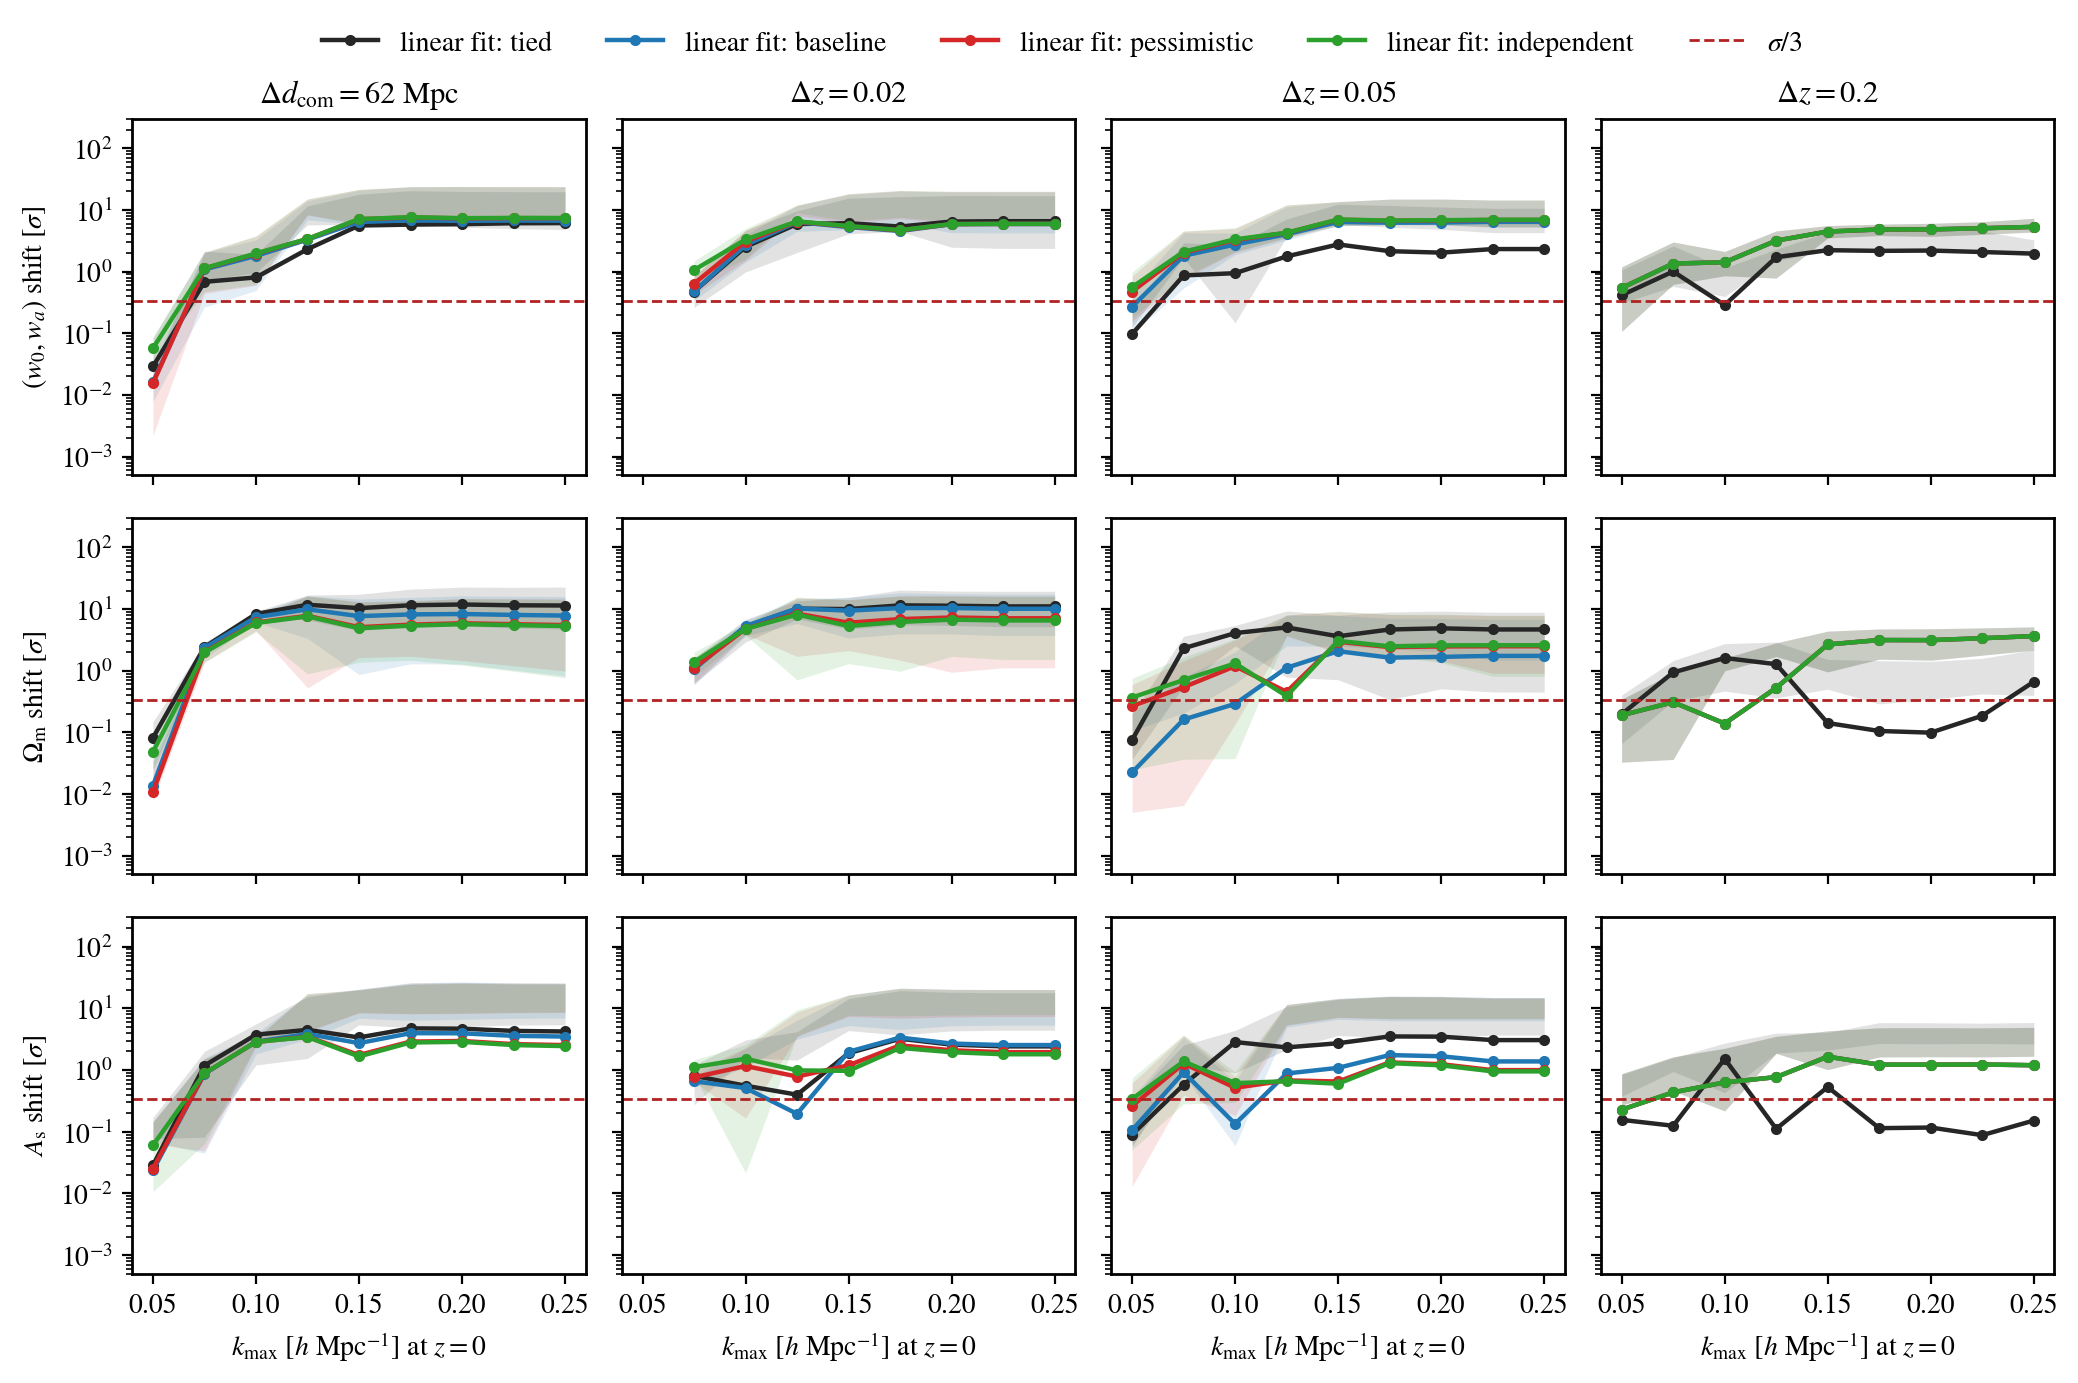

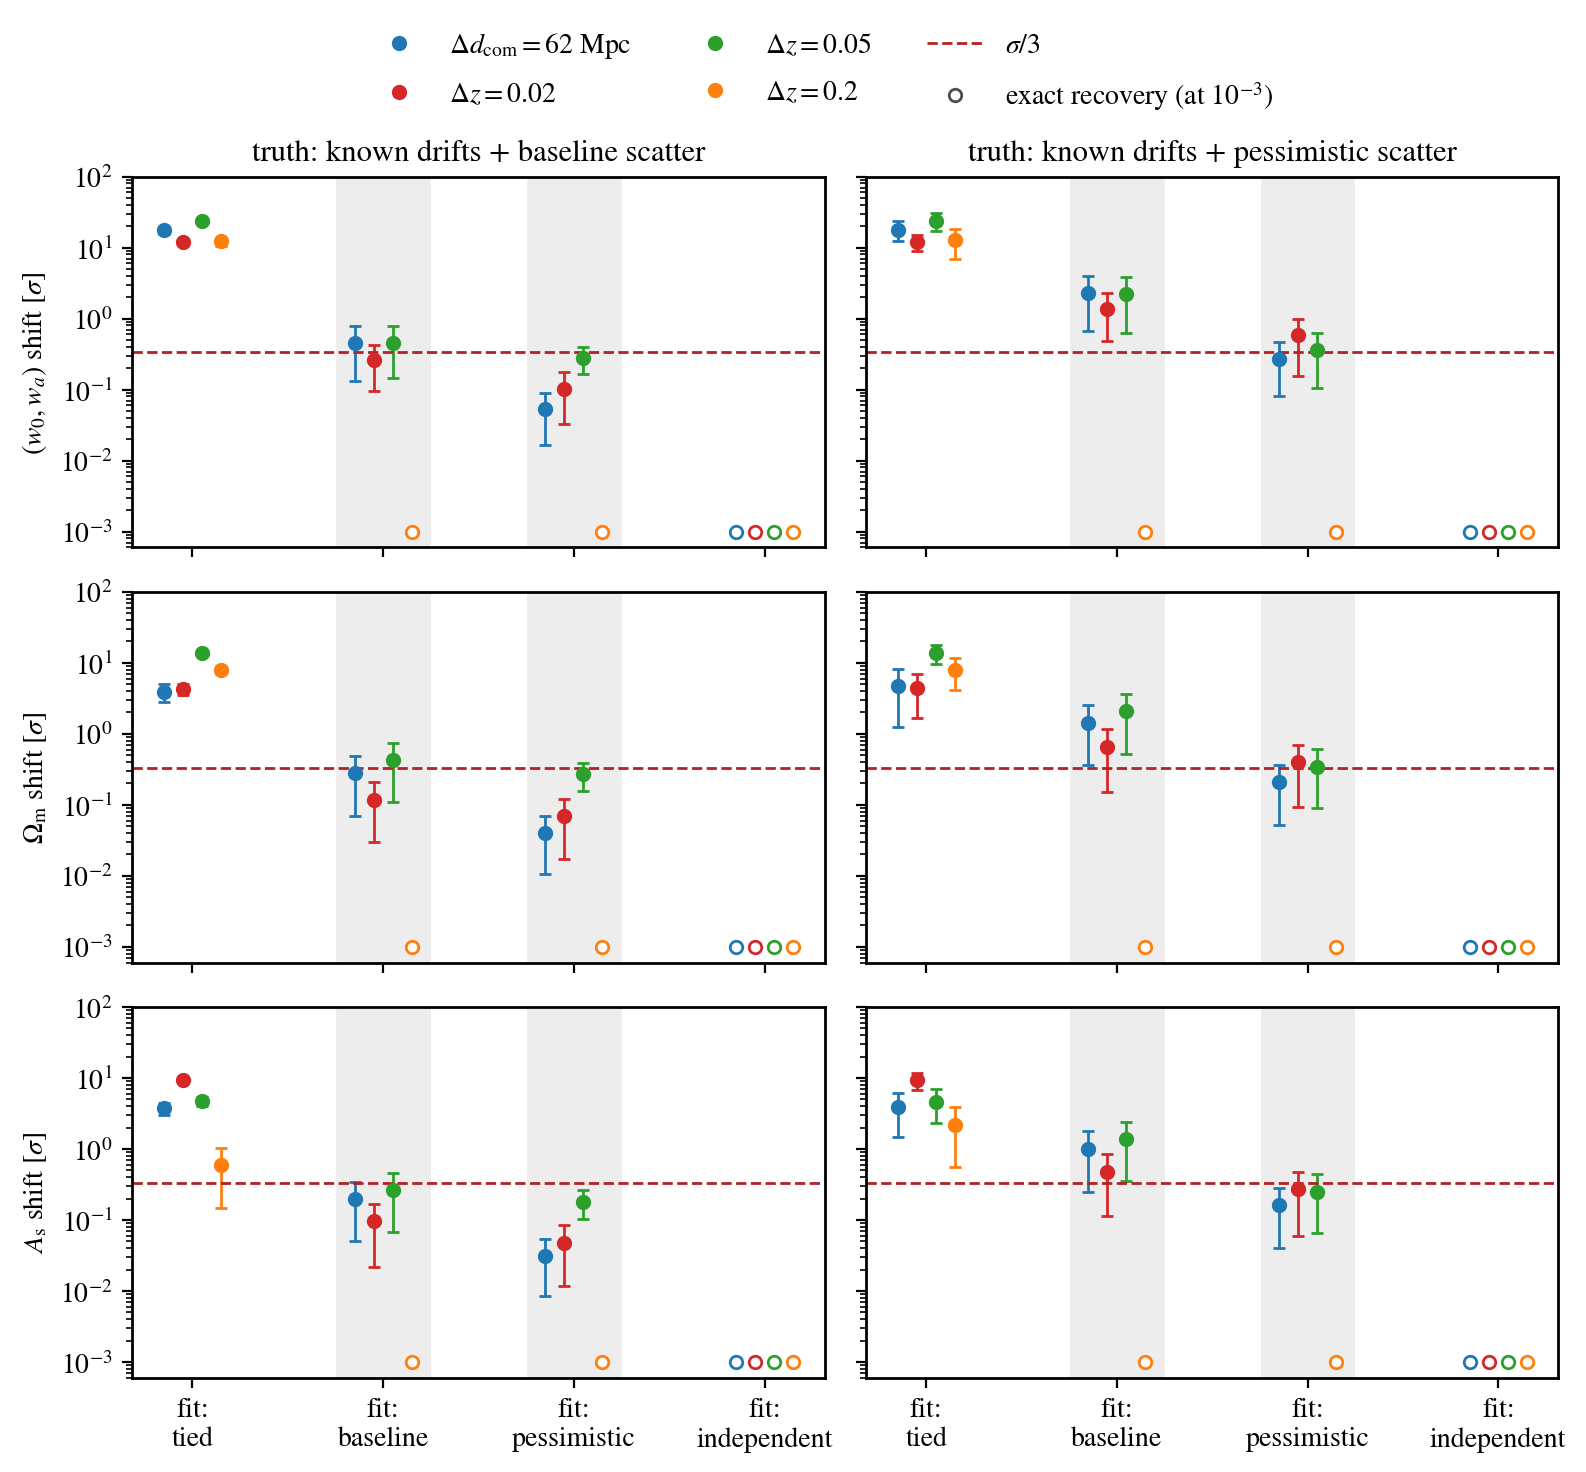

In [8]:
fob_data = {
    'about': ('figure of bias of a linear-bias fit to a one-loop (model A) truth against '
              'the UV-fraction cut k_max, per layout and linear rung: (w0, wa) in its '
              'ellipse, Omega_m and A_s in their own marginalized sigma. Written by '
              'EXAMPLE_EVALUATE_FISHER_LINEAR_KMAX.ipynb.'),
    'kmax_h_per_Mpc': [float(k) for k in KMAX_CUTS], 'shift_threshold': SHIFT_THRESHOLD,
    'rungs': LADDER_RUNGS, 'truths': list(TRUTHS), 'params': ['w0wa', *SINGLE_PARAMS],
    'layouts': [{'name': key, 'label': LAYOUT_LABELS[key], 'color': LAYOUT_COLORS[key],
                 'shift': {rung: {truth: [scan[(key, rung, truth, m)]
                                          for m in range(len(KMAX_CUTS))]
                                  for truth in TRUTHS} for rung in LADDER_RUNGS},
                 'safe_kmax': {rung: safe[(key, rung)] for rung in LADDER_RUNGS}}
                for key in LAYOUTS],
}
v1_data = {
    'about': ('the accuracy test of notes/correlated_bias_prior at its k_max, scored for '
              '(w0, wa), Omega_m and A_s: shifts of the known drifts, and the mean, '
              '16-84 percentiles and error inflation over the random truths. Written by '
              'EXAMPLE_EVALUATE_FISHER_LINEAR_KMAX.ipynb.'),
    'kmax_h_per_Mpc': float(KMAX_CUTS[m_v1]), 'shift_threshold': SHIFT_THRESHOLD,
    'rungs': LADDER_RUNGS, 'truths': list(BIAS_ASSUMPTIONS), 'drift_laws': DRIFT_LAWS,
    'params': ['w0wa', *SINGLE_PARAMS],
    'layouts': [{'name': key, 'label': LAYOUT_LABELS[key], 'color': LAYOUT_COLORS[key],
                 'fits': {rung: v1[(key, rung)] for rung in LADDER_RUNGS}}
                for key in LAYOUTS],
}
for name, data in (('fob_kmax', fob_data), ('ladder_bias_params', v1_data)):
    os.makedirs(NOTE_PLOTS + name, exist_ok=True)
    with open(NOTE_PLOTS + name + '/data.json', 'w') as f:
        json.dump(data, f, indent=1)
    script = NOTE_PLOTS + name + f'/plot_{name}.py'
    if os.path.exists(script):
        subprocess.run([sys.executable, script], check=True)
        display(Image(filename=NOTE_PLOTS + name + f'/{name}.png', width=720))

## 7. Conclusion

Linear bias is acceptable only at $k_\mathrm{max} \leq 0.05\,h/\mathrm{Mpc}$, and of
the four layouts robustly, on every rung and for every truth, only on
$\Delta d_\mathrm{com} = 62$ Mpc. That cut is expensive: on that layout the
${\rm FoM}(w_0, w_a)$ falls from $32.9$, $18.2$, $11.4$ and $10.7$ at $0.075$ to
$2.19$, $1.54$, $0.855$ and $0.145$ at $0.05$ (tied, baseline, pessimistic,
independent; the `fom` entries of `fob_kmax/data.json`). At the v1 note's cut,
$k_\mathrm{max} = 0.075\,h/\mathrm{Mpc}$, the forecast should therefore use the
one-loop model A. The companion note `notes/correlated_bias_prior_v2`, with
`EXAMPLE_EVALUATE_FISHER_MODEL_A.ipynb`, redoes the bias-prior ladder and its
accuracy test under model A.

All $k_\mathrm{max}$ above are quoted at $z = 0$; each bin is cut by the
UV-fraction criterion at $k_\mathrm{max}/D(\bar z_i)$ ($\alpha = 0.05$) within the
shipped mask.